# Credit Portfolio Segmentation and Risk Pattern Analysis
## Step 2: Data Preprocessing

This step covers:

1. Missing values
2. Duplicate records
3. Inconsistent values
4. Outlier investigation and treatment
5. Removing irrelevant identifiers
6. Selecting suitable clustering features, then encoding and scaling them

**Project rule:** `Default` is kept out of the clustering features. It is preserved separately (with the loan ID, state, issue date and the original revenue and DTI values) so that, after clustering, historical default rates can be compared across borrower segments.

## 1. Load the data and create working copies

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", None)

DATA_PATH = r"D:\HCL_PROJECTS\Credit Portfolio Segmentation and Risk Pattern Analysis Project-3\loans_granting_model_dataset.csv"
OUTPUT_DIR = Path("step2_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# low_memory=False avoids the mixed-type DtypeWarning on the 'desc' column
df_raw = pd.read_csv(DATA_PATH, low_memory=False)

print("Dataset loaded successfully")
print("Shape:", df_raw.shape)
display(df_raw.head())

# Keep the original untouched; all cleaning happens on a copy
df_clean = df_raw.copy()
print("\nWorking copy shape:", df_clean.shape)

Dataset loaded successfully
Shape: (1347681, 15)


,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,zip_code,Default,title,desc
0,68407277,Dec-2015,55000.0,5.91,3600,677.0,1,10+ years,debt_consolidation,MORTGAGE,PA,190xx,0,Debt consolidation,NaN
1,68355089,Dec-2015,65000.0,16.06,24700,717.0,1,10+ years,small_business,MORTGAGE,SD,577xx,0,Business,NaN
2,68341763,Dec-2015,71000.0,13.85,20000,697.0,1,10+ years,home_improvement,MORTGAGE,IL,605xx,0,NaN,NaN
3,68476807,Dec-2015,104433.0,25.37,10400,697.0,1,3 years,major_purchase,MORTGAGE,PA,174xx,0,Major purchase,NaN
4,68426831,Dec-2015,34000.0,10.20,11950,692.0,1,4 years,debt_consolidation,RENT,GA,300xx,0,Debt consolidation,NaN



Working copy shape: (1347681, 15)


## 2. Missing values

In [2]:
missing_report = pd.DataFrame({
    "Missing_Count": df_clean.isnull().sum(),
    "Missing_Percentage": (df_clean.isnull().mean() * 100).round(3),
}).sort_values("Missing_Percentage", ascending=False)

display(missing_report)

,Missing_Count,Missing_Percentage
desc,1228582,91.163
title,16657,1.236
id,0,0.000
dti_n,0,0.000
loan_amnt,0,0.000
issue_d,0,0.000
revenue,0,0.000
experience_c,0,0.000
fico_n,0,0.000
emp_length,0,0.000


### Missing-value decisions

Every financial, credit, employment and loan feature is complete, so no imputation is needed for them. Only three descriptive columns have gaps, and none of them is a clustering input:

| Column | Missing | Decision |
|---|---|---|
| `desc` | 91.163% | Drop (too sparse to use) |
| `title` | 1.236% | Drop (overlaps `purpose`) |
| `zip_code` | 1 record | Drop from clustering (945 masked prefixes; `addr_state` covers geography) |

The columns are removed together in the feature-selection step (section 6).

## 3. Duplicate records

In [3]:
print("Complete duplicate rows:", df_clean.duplicated().sum())
print("Duplicate loan IDs     :", df_clean["id"].duplicated().sum())
print("Missing loan IDs       :", df_clean["id"].isnull().sum())

Complete duplicate rows: 0
Duplicate loan IDs     : 0
Missing loan IDs       : 0


No duplicate rows or loan IDs exist, so no records are removed. The `id` column is an identifier, not a borrower characteristic, so it is excluded from clustering (and preserved for later joins).

## 4. Inconsistent values

In [4]:
categorical_cols = ["emp_length", "purpose", "home_ownership_n", "addr_state"]

# Remove stray whitespace from the text categories
for col in categorical_cols:
    df_clean[col] = df_clean[col].astype("string").str.strip()

# Category counts (Step 1: 12 emp_length, 14 purpose, 4 home ownership, 51 states)
for col in categorical_cols:
    print(f"{col}: {df_clean[col].nunique()} categories")

# Employment labels must match the encoding map used in section 7
EXPECTED_EMP = {
    "< 1 year", "1 year", "2 years", "3 years", "4 years", "5 years",
    "6 years", "7 years", "8 years", "9 years", "10+ years", "NI",
}
unexpected_emp = set(df_clean["emp_length"].dropna().unique()) - EXPECTED_EMP
print("\nUnexpected emp_length labels:", unexpected_emp or "none")

# Range checks on the numeric fields
print("\nRange checks")
print("revenue <= 0        :", (df_clean["revenue"] <= 0).sum())
print("loan_amnt <= 0      :", (df_clean["loan_amnt"] <= 0).sum())
print("dti_n < 0           :", (df_clean["dti_n"] < 0).sum())
print("fico_n outside 300-850:", (~df_clean["fico_n"].between(300, 850)).sum())
print("fico_n with .5 values :", (df_clean["fico_n"] % 1 != 0).sum())
print("\nValues among the .5 records:")
print(df_clean.loc[df_clean["fico_n"] % 1 != 0, "fico_n"].value_counts())

emp_length: 12 categories
purpose: 14 categories
home_ownership_n: 4 categories
addr_state: 51 categories

Unexpected emp_length labels: none

Range checks
revenue <= 0        : 0
loan_amnt <= 0      : 0
dti_n < 0           : 0
fico_n outside 300-850: 0
fico_n with .5 values : 185

Values among the .5 records:
fico_n
847.5    185
Name: count, dtype: int64


### Inconsistent-value findings

- Text categories are trimmed. The label for employment under one year is `"< 1 year"` (with a space), and the encoding in section 7 uses exactly that spelling.
- There are no impossible numeric values: no zero or negative income or loan amount, no negative DTI, and no FICO score outside 300 to 850.
- `fico_n` contains .5 values (185 borrowers; the top value is 847.5). This is consistent with a score averaged over a low and high range, so these are kept as valid scores.

## 5. Outlier investigation and treatment

In [5]:
# Definitions used throughout (same as Step 1)
DTI_EXTREME = 100   # DTI at or above this is treated as implausible
DTI_CAP = 65        # cap value; the 99.9th percentile of DTI is about 66 (1,410 rows lie above 65)

print("REVENUE")
for threshold in [500_000, 1_000_000, 5_000_000]:
    print(f"  revenue > {threshold:>9,}: {(df_clean['revenue'] > threshold).sum():,}")
print(df_clean["revenue"].quantile([0.90, 0.95, 0.99, 0.995, 0.999, 1.0]).to_string())

print("\nDTI")
for threshold in [40, 50, 65, 100, 200, 500]:
    n = (df_clean["dti_n"] > threshold).sum()
    print(f"  dti_n > {threshold:>3}: {n:>6,} records ({n / len(df_clean) * 100:.4f}%)")
print("  dti_n == 999 :", (df_clean["dti_n"] == 999).sum())
print("  dti_n >= 100 :", (df_clean["dti_n"] >= DTI_EXTREME).sum())
print("  dti_n == 0   :", (df_clean["dti_n"] == 0).sum())
print("  99.9th percentile:", round(df_clean["dti_n"].quantile(0.999), 2))

print("\nFICO")
print("  above 800:", (df_clean["fico_n"] > 800).sum())
print("  above 850:", (df_clean["fico_n"] > 850).sum())
print("  below 600:", (df_clean["fico_n"] < 600).sum())

print("\nHighest DTI records:")
display(df_clean.nlargest(10, "dti_n")[["id", "dti_n", "revenue", "loan_amnt", "fico_n"]])

print("Highest revenue records:")
display(df_clean.nlargest(10, "revenue")[["id", "revenue", "dti_n", "loan_amnt", "fico_n"]])

REVENUE
  revenue >   500,000: 1,789
  revenue > 1,000,000: 294
  revenue > 5,000,000: 41
0.900      129000.0
0.950      160000.0
0.990      260000.0
0.995      325000.0
0.999      585000.0
1.000    10999200.0

DTI
  dti_n >  40:  6,804 records (0.5049%)
  dti_n >  50:  2,780 records (0.2063%)
  dti_n >  65:  1,410 records (0.1046%)
  dti_n > 100:    533 records (0.0395%)
  dti_n > 200:    199 records (0.0148%)
  dti_n > 500:     71 records (0.0053%)
  dti_n == 999 : 38
  dti_n >= 100 : 535
  dti_n == 0   : 835
  99.9th percentile: 66.0

FICO
  above 800: 15445
  above 850: 0
  below 600: 0

Highest DTI records:


,id,dti_n,revenue,loan_amnt,fico_n
7767,67405134,999.0,62151.0,6550,672.0
381305,129679050,999.0,78800.0,8000,687.0
386273,127916653,999.0,66633.0,10250,712.0
394079,126388240,999.0,126665.0,14225,752.0
398115,120060219,999.0,58800.0,15000,717.0
398172,119987558,999.0,153000.0,26000,762.0
402650,119333994,999.0,76000.0,21000,692.0
404149,115381037,999.0,138100.0,10000,722.0
411443,117560607,999.0,160300.0,35000,672.0
417509,116709237,999.0,145600.0,35000,677.0


Highest revenue records:


,id,revenue,dti_n,loan_amnt,fico_n
401581,118198788,10999200.0,0.07,5000,687.0
574869,74682106,9550000.0,0.07,30000,807.0
974244,99577890,9522972.0,0.32,35000,712.0
203890,54067210,9500000.0,0.12,24000,727.0
902723,134767124,9300000.0,0.02,8400,672.0
497338,76301759,9225000.0,0.11,11600,667.0
35666,65945334,9000000.0,0.08,11000,707.0
191930,55140826,8900060.0,0.09,10550,692.0
356764,39429853,8706582.0,0.11,8000,687.0
21834,66605376,8700000.0,0.18,14000,687.0


In [6]:
# Default is inspected here only to decide how to treat outliers. It is never used as a feature.
overall = df_clean["Default"].mean() * 100
print(f"Overall default rate: {overall:.2f}%\n")

checks = {
    f"dti_n >= {DTI_EXTREME}": df_clean["dti_n"] >= DTI_EXTREME,
    "dti_n == 0": df_clean["dti_n"] == 0,
    "revenue > 1,000,000": df_clean["revenue"] > 1_000_000,
}
rows = []
for label, mask in checks.items():
    rows.append({
        "Group": label,
        "Records": int(mask.sum()),
        "Default_Rate_%": round(df_clean.loc[mask, "Default"].mean() * 100, 2),
    })
display(pd.DataFrame(rows))

Overall default rate: 19.98%



,Group,Records,Default_Rate_%
0,dti_n >= 100,535,26.73
1,dti_n == 0,835,19.40
2,"revenue > 1,000,000",294,13.27


### Outlier decisions

No record is deleted. High incomes, large loans and high FICO scores are legitimate borrower profiles, and the extreme DTI group carries risk information.

| Feature | Finding | Treatment |
|---|---|---|
| `revenue` | Strongly right-skewed (max $10,999,200; 1,789 rows above $500,000; 294 above $1M; the largest values are round numbers, suggesting self-reported figures) | Apply `log1p`; keep all rows |
| `dti_n` | 38 rows equal 999 and 533 are above 100, with a long tail up to 991.57; the 99.9th percentile is about 66 | Cap at 65 so that extreme rows stay at the top of the range without dominating distances; do not impute the median |
| DTI flag | Rows with DTI of 100 or more default at 26.73% against 19.98% overall | Save `dti_extreme` for cluster profiling |
| `loan_amnt` | Capped at $40,000 by the product | Retain, scale |
| `fico_n` | High-side outliers are good scores; none above 850 | Retain, scale |

**Other groups checked:** DTI = 0 (835 rows) defaults at 19.40%, in line with the 19.98% portfolio rate, so it is left untouched; revenue above $1M (294 rows) defaults at 13.27%, below the portfolio rate, so these borrowers are kept and compressed with `log1p`.

**Why capping, not median imputation:** replacing a DTI of 800 with the median (17.63) makes a high-risk borrower look average and hides a real signal. Capping limits the influence on K-Means and DBSCAN while keeping the borrower at the high end of the scale.

## 6. Remove identifiers and select clustering features

In [7]:
# --- 6a. Preserve everything needed AFTER clustering (never used as a feature) ---
df_audit = pd.DataFrame({
    "id": df_clean["id"],
    "Default": df_clean["Default"],
    "addr_state": df_clean["addr_state"],
    "issue_d": pd.to_datetime(df_clean["issue_d"], format="%b-%Y", errors="coerce"),
    "revenue_original": df_clean["revenue"],
    "dti_original": df_clean["dti_n"],
    "dti_extreme": (df_clean["dti_n"] >= DTI_EXTREME).astype("int8"),
})
df_audit["issue_year"] = df_audit["issue_d"].dt.year
df_audit["issue_month"] = df_audit["issue_d"].dt.month

print("Unparsed issue dates:", df_audit["issue_d"].isnull().sum())
print("Audit table shape   :", df_audit.shape)

# --- 6b. Columns excluded from clustering ---
excluded = pd.DataFrame(
    [
        ("id", "Identifier, not a borrower characteristic"),
        ("Default", "Outcome; held out for post-clustering risk profiling"),
        ("experience_c", "Near constant (25 zeros) and inconsistent with emp_length"),
        ("zip_code", "945 masked prefixes; addr_state covers geography; 1 missing value"),
        ("title", "1.236% missing and overlaps purpose"),
        ("desc", "91.163% missing"),
        ("issue_d", "Time attribute; kept in the audit table for time-based checks"),
        ("addr_state", "Tested separately with and without; kept in the audit table"),
    ],
    columns=["Column", "Reason excluded"],
)
display(excluded)

Unparsed issue dates: 0
Audit table shape   : (1347681, 9)


,Column,Reason excluded
0,id,"Identifier, not a borrower characteristic"
1,Default,Outcome; held out for post-clustering risk profiling
2,experience_c,Near constant (25 zeros) and inconsistent with emp_length
3,zip_code,945 masked prefixes; addr_state covers geography; 1 missing value
4,title,1.236% missing and overlaps purpose
5,desc,91.163% missing
6,issue_d,Time attribute; kept in the audit table for time-based checks
7,addr_state,Tested separately with and without; kept in the audit table


### Selected clustering features

- **Numeric:** `revenue` (log-transformed), `dti_n` (capped), `loan_amnt`, `fico_n`
- **Employment:** `emp_length` as years plus an unknown flag
- **Categorical:** `purpose` and `home_ownership_n`, one-hot encoded

## 7. Feature engineering and encoding

In [8]:
# Employment length: ordinal years, with "NI" (not provided) kept as its own flag
EMP_LENGTH_MAP = {
    "< 1 year": 0.5,
    "1 year": 1, "2 years": 2, "3 years": 3, "4 years": 4, "5 years": 5,
    "6 years": 6, "7 years": 7, "8 years": 8, "9 years": 9,
    "10+ years": 10,
}

emp_numeric = df_clean["emp_length"].map(EMP_LENGTH_MAP).astype("float64")
emp_unknown = df_clean["emp_length"].eq("NI")

# Every label must be either mapped or NI; anything else is a bug
unmapped = df_clean.loc[emp_numeric.isna() & ~emp_unknown, "emp_length"].unique()
assert len(unmapped) == 0, f"Unmapped emp_length labels: {unmapped}"

emp_median = emp_numeric.median()
print("Median employment length of known values:", emp_median)
print("NI records:", int(emp_unknown.sum()))

# Build the model input from an explicit list of selected features
df_model_input = pd.DataFrame({
    "dti_n": df_clean["dti_n"].clip(upper=DTI_CAP),
    "loan_amnt": df_clean["loan_amnt"],
    "fico_n": df_clean["fico_n"],
    "revenue_log": np.log1p(df_clean["revenue"]),
    # NI rows get the median years; emp_length_unknown records that they are unknown
    "emp_length_years": emp_numeric.fillna(emp_median),
    "emp_length_unknown": emp_unknown.astype("int8"),
    "purpose": df_clean["purpose"],
    "home_ownership_n": df_clean["home_ownership_n"],
})

print("\nRecords capped at DTI", DTI_CAP, ":", int((df_clean["dti_n"] > DTI_CAP).sum()))
print("Revenue skewness  raw -> log:",
      round(df_clean["revenue"].skew(), 2), "->", round(df_model_input["revenue_log"].skew(), 2))
print("Missing values in model input:", int(df_model_input.isnull().sum().sum()))

Median employment length of known values: 6.0
NI records: 78188

Records capped at DTI 65 : 1410
Revenue skewness  raw -> log: 45.4 -> 0.21
Missing values in model input: 0


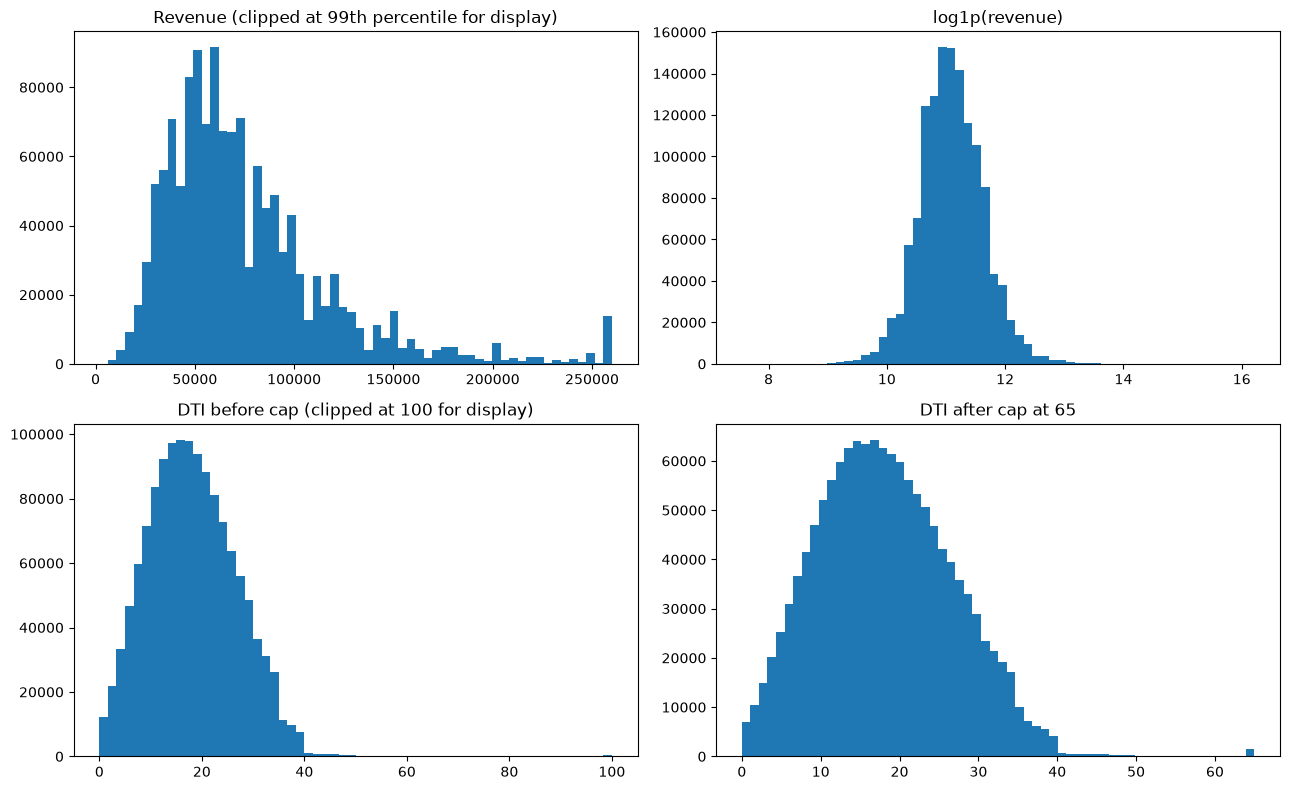

In [9]:
# Before and after views of the two treated features
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

axes[0, 0].hist(df_clean["revenue"].clip(upper=df_clean["revenue"].quantile(0.99)), bins=60)
axes[0, 0].set_title("Revenue (clipped at 99th percentile for display)")

axes[0, 1].hist(df_model_input["revenue_log"], bins=60)
axes[0, 1].set_title("log1p(revenue)")

axes[1, 0].hist(df_clean["dti_n"].clip(upper=100), bins=60)
axes[1, 0].set_title("DTI before cap (clipped at 100 for display)")

axes[1, 1].hist(df_model_input["dti_n"], bins=60)
axes[1, 1].set_title(f"DTI after cap at {DTI_CAP}")

plt.tight_layout()
plt.show()

In [10]:
# One-hot encode purpose and home ownership (all categories kept, which suits distance-based clustering)
df_encoded = pd.get_dummies(
    df_model_input,
    columns=["purpose", "home_ownership_n"],
    prefix=["purpose", "home"],
    dtype=np.int8,
)

print("Encoded shape:", df_encoded.shape)
print("\nColumns:")
print(df_encoded.columns.tolist())

continuous_cols = ["dti_n", "loan_amnt", "fico_n", "revenue_log", "emp_length_years"]
binary_cols = [c for c in df_encoded.columns if c not in continuous_cols]
print(f"\nContinuous: {len(continuous_cols)}  |  Binary: {len(binary_cols)}  |  Total: {df_encoded.shape[1]}")

assert df_encoded.shape[1] == 24, "Expected 5 continuous + 19 binary = 24 features"

Encoded shape: (1347681, 24)

Columns:
['dti_n', 'loan_amnt', 'fico_n', 'revenue_log', 'emp_length_years', 'emp_length_unknown', 'purpose_car', 'purpose_credit_card', 'purpose_debt_consolidation', 'purpose_educational', 'purpose_home_improvement', 'purpose_house', 'purpose_major_purchase', 'purpose_medical', 'purpose_moving', 'purpose_other', 'purpose_renewable_energy', 'purpose_small_business', 'purpose_vacation', 'purpose_wedding', 'home_MORTGAGE', 'home_OTHER', 'home_OWN', 'home_RENT']

Continuous: 5  |  Binary: 19  |  Total: 24


## 8. Feature scaling

In [11]:
# Standardize only the continuous features; binary columns stay 0/1
scaler = StandardScaler()

df_scaled = df_encoded.copy()
df_scaled[continuous_cols] = scaler.fit_transform(df_encoded[continuous_cols])

print("Scaled feature statistics:")
display(df_scaled[continuous_cols].agg(["mean", "std", "min", "max"]).round(3))

Scaled feature statistics:


,dti_n,loan_amnt,fico_n,revenue_log,emp_length_years
mean,-0.000,0.000,-0.000,0.000,0.000
std,1.000,1.000,1.000,1.000,1.000
min,-2.101,-1.596,-2.705,-6.597,-1.565
max,5.397,2.936,4.689,9.499,1.136


In [12]:
# How many borrowers are still extreme after scaling? (|z| > 5)
extreme_counts = (df_scaled[continuous_cols].abs() > 5).sum()
print("Records with |z| > 5 per continuous feature:")
print(extreme_counts.to_string())

Records with |z| > 5 per continuous feature:
dti_n               1606
loan_amnt              0
fico_n                 0
revenue_log          389
emp_length_years       0


### Scaling notes

- The five continuous features now have mean 0 and standard deviation 1; the 19 one-hot and flag columns remain 0/1.
- After capping, `dti_n` reaches a maximum z-score of about 5.4 (it was about 9.4 without a cap). `revenue_log` still has extreme values at both ends (z-scores from about -6.6 to +9.5), so inspect cluster membership of these borrowers in Step 3.
- Nineteen binary columns (14 for `purpose`) against five continuous ones means loan purpose can dominate distance calculations. Check cluster stability, or weight the binary columns.

## 9. Final validation

In [13]:
# 1. Data types
non_numeric = df_scaled.select_dtypes(exclude=["number"]).columns.tolist()
print("Non-numeric columns:", non_numeric)

# 2. Missing and infinite values
print("Missing values :", int(df_scaled.isnull().sum().sum()))
print("Infinite values:", int(np.isinf(df_scaled.to_numpy(dtype="float64")).sum()))

# 3. Binary columns hold only 0/1
invalid_binary = {c: df_scaled[c].unique() for c in binary_cols if not df_scaled[c].isin([0, 1]).all()}
print("\nBinary columns:", len(binary_cols), "| invalid:", invalid_binary or "none")

# 4. Constant columns
constant_cols = [c for c in df_scaled.columns if df_scaled[c].nunique() <= 1]
print("Constant columns:", constant_cols or "none")

# 5. Row alignment with the audit table (no rows were dropped)
assert len(df_scaled) == len(df_audit) == len(df_raw)
assert (df_scaled.index == df_audit.index).all()
print("\nFinal shape:", df_scaled.shape)
print("Rows preserved:", len(df_scaled) == len(df_raw))

Non-numeric columns: []
Missing values : 0
Infinite values: 0

Binary columns: 19 | invalid: none
Constant columns: none

Final shape: (1347681, 24)
Rows preserved: True


## 10. Save outputs for Step 3

In [14]:
def save_table(frame, name):
    """Save as parquet when available, otherwise CSV. Row order is preserved."""
    try:
        path = OUTPUT_DIR / f"{name}.parquet"
        frame.to_parquet(path)
    except Exception:
        path = OUTPUT_DIR / f"{name}.csv"
        frame.to_csv(path, index=False)
    return path.name


saved = {
    "scaled_features": save_table(df_scaled, "clustering_features_scaled"),
    "audit_table": save_table(df_audit, "audit_table"),
}
joblib.dump(scaler, OUTPUT_DIR / "standard_scaler.joblib")

with open(OUTPUT_DIR / "feature_lists.json", "w") as f:
    json.dump({"continuous": continuous_cols, "binary": binary_cols,
               "dti_cap": DTI_CAP, "dti_extreme_threshold": DTI_EXTREME}, f, indent=2)

print("Saved to", OUTPUT_DIR.resolve())
for k, v in saved.items():
    print(f"  {k}: {v}")
print("  scaler: standard_scaler.joblib")
print("  feature lists: feature_lists.json")

Saved to D:\HCL_PROJECTS\Credit Portfolio Segmentation and Risk Pattern Analysis Project-3\step2_outputs
  scaled_features: clustering_features_scaled.parquet
  audit_table: audit_table.parquet
  scaler: standard_scaler.joblib
  feature lists: feature_lists.json


In [15]:
print("Current working directory:", Path.cwd())
print("Output directory:", OUTPUT_DIR.resolve())

print("\nFiles saved:")
for file in OUTPUT_DIR.iterdir():
    print(file.name)

Current working directory: D:\HCL_PROJECTS\Credit Portfolio Segmentation and Risk Pattern Analysis Project-3
Output directory: D:\HCL_PROJECTS\Credit Portfolio Segmentation and Risk Pattern Analysis Project-3\step2_outputs

Files saved:
audit_table.parquet
clustering_features_scaled.parquet
feature_lists.json
standard_scaler.joblib


In [16]:
import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path("step2_outputs")

df_audit = pd.read_parquet(OUTPUT_DIR / "audit_table.parquet")
df_scaled = pd.read_parquet(OUTPUT_DIR / "clustering_features_scaled.parquet")

# View first 10 rows
display(df_audit.head(10))

display(df_scaled.head(10))

,id,Default,addr_state,issue_d,revenue_original,dti_original,dti_extreme,issue_year,issue_month
0,68407277,0,PA,2015-12-01,55000.0,5.91,0,2015,12
1,68355089,0,SD,2015-12-01,65000.0,16.06,0,2015,12
2,68341763,0,IL,2015-12-01,71000.0,13.85,0,2015,12
3,68476807,0,PA,2015-12-01,104433.0,25.37,0,2015,12
4,68426831,0,GA,2015-12-01,34000.0,10.20,0,2015,12
5,68476668,0,MN,2015-12-01,180000.0,14.67,0,2015,12
6,67275481,0,SC,2015-12-01,85000.0,17.61,0,2015,12
7,68466926,0,PA,2015-12-01,85000.0,13.07,0,2015,12
8,68616873,0,RI,2015-12-01,42000.0,34.80,0,2015,12
9,68338832,0,NC,2015-12-01,64000.0,34.95,0,2015,12


,dti_n,loan_amnt,fico_n,revenue_log,emp_length_years,emp_length_unknown,purpose_car,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_house,purpose_major_purchase,purpose_medical,purpose_moving,purpose_other,purpose_renewable_energy,purpose_small_business,purpose_vacation,purpose_wedding,home_MORTGAGE,home_OTHER,home_OWN,home_RENT
0,-1.418948,-1.240138,-0.664357,-0.342488,1.135675,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
1,-0.248168,1.180879,0.591581,-0.032196,1.135675,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0
2,-0.503086,0.641601,-0.036388,0.131801,1.135675,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0
3,0.825720,-0.459905,-0.036388,0.848524,-0.854051,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0
4,-0.924106,-0.282058,-0.193381,-1.235855,-0.569805,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
5,-0.408501,0.641601,-0.507365,1.859739,1.135675,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
6,-0.069379,0.641601,0.277596,0.466087,1.135675,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0
7,-0.593058,-0.505801,-0.350373,0.466087,-0.001312,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
8,1.913450,-0.735281,0.120604,-0.843367,1.135675,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
9,1.930752,-1.492566,0.120604,-0.060994,-0.854051,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0


In [17]:
print("Shape:", df_audit.shape)
print("\nColumn names:")
print(df_audit.columns.tolist())

print("\nData types:")
print(df_audit.dtypes)

print("\nMissing values:")
display(df_audit.isnull().sum())

print("\nStatistical summary:")
display(df_audit.describe(include="all").T)

Shape: (1347681, 9)

Column names:
['id', 'Default', 'addr_state', 'issue_d', 'revenue_original', 'dti_original', 'dti_extreme', 'issue_year', 'issue_month']

Data types:
id                           int64
Default                      int64
addr_state                  string
issue_d             datetime64[us]
revenue_original           float64
dti_original               float64
dti_extreme                   int8
issue_year                   int32
issue_month                  int32
dtype: object

Missing values:


id                  0
Default             0
addr_state          0
issue_d             0
revenue_original    0
dti_original        0
dti_extreme         0
issue_year          0
issue_month         0
dtype: int64


Statistical summary:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
id,1347681.0,NaN,NaN,NaN,56213593.228885,54734.0,19706506.0,57664225.0,84495046.0,145636374.0,38395009.681332
Default,1347681.0,NaN,NaN,NaN,0.199787,0.0,0.0,0.0,0.0,1.0,0.39984
addr_state,1347681,51,CA,196805,NaN,NaN,NaN,NaN,NaN,NaN,NaN
issue_d,1347681,NaN,NaN,NaN,2015-06-01 22:05:17.136770,2007-06-01 00:00:00,2014-07-01 00:00:00,2015-08-01 00:00:00,2016-07-01 00:00:00,2018-12-01 00:00:00,NaN
revenue_original,1347681.0,NaN,NaN,NaN,77369.683174,1896.0,46600.0,65000.0,92000.0,10999200.0,70362.989597
dti_original,1347681.0,NaN,NaN,NaN,18.299091,0.0,11.82,17.63,24.07,999.0,11.152139
dti_extreme,1347681.0,NaN,NaN,NaN,0.000397,0.0,0.0,0.0,0.0,1.0,0.01992
issue_year,1347681.0,NaN,NaN,NaN,2014.958567,2007.0,2014.0,2015.0,2016.0,2018.0,1.661849
issue_month,1347681.0,NaN,NaN,NaN,6.508805,1.0,3.0,7.0,10.0,12.0,3.450132


In [18]:
df_audit.to_csv(
    OUTPUT_DIR / "audit_table.csv",
    index=False
)

df_scaled.to_csv(
    OUTPUT_DIR / "clustering_features_scaled.csv",
    index=False
)

print("CSV files created successfully!")

CSV files created successfully!


In [19]:

# ==========================================
# SAVE COMPLETE CLEANED DATASET
# ==========================================

# Keep original borrower and loan features for EDA.
# Remove descriptive columns that are not useful for analysis.
df_cleaned_full = df_clean.drop(
    columns=["desc", "title", "zip_code"],
    errors="ignore"
).copy()

# Add useful engineered columns while retaining original values
df_cleaned_full["revenue_log"] = np.log1p(df_cleaned_full["revenue"])

df_cleaned_full["dti_capped"] = (
    df_cleaned_full["dti_n"].clip(upper=DTI_CAP)
)

df_cleaned_full["dti_extreme"] = (
    df_cleaned_full["dti_n"] >= DTI_EXTREME
).astype("int8")

# Save the complete cleaned dataset
cleaned_path = save_table(
    df_cleaned_full,
    "cleaned_credit_portfolio"
)

print("Cleaned dataset saved successfully!")
print("File:", OUTPUT_DIR / cleaned_path)
print("Shape:", df_cleaned_full.shape)

display(df_cleaned_full.head())


Cleaned dataset saved successfully!
File: step2_outputs\cleaned_credit_portfolio.parquet
Shape: (1347681, 15)


,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,Default,revenue_log,dti_capped,dti_extreme
0,68407277,Dec-2015,55000.0,5.91,3600,677.0,1,10+ years,debt_consolidation,MORTGAGE,PA,0,10.915107,5.91,0
1,68355089,Dec-2015,65000.0,16.06,24700,717.0,1,10+ years,small_business,MORTGAGE,SD,0,11.082158,16.06,0
2,68341763,Dec-2015,71000.0,13.85,20000,697.0,1,10+ years,home_improvement,MORTGAGE,IL,0,11.170449,13.85,0
3,68476807,Dec-2015,104433.0,25.37,10400,697.0,1,3 years,major_purchase,MORTGAGE,PA,0,11.556311,25.37,0
4,68426831,Dec-2015,34000.0,10.20,11950,692.0,1,4 years,debt_consolidation,RENT,GA,0,10.434145,10.20,0


In [20]:

import pandas as pd
from pathlib import Path

# Your project output folder
OUTPUT_DIR = Path(
    r"D:\HCL_PROJECTS\Credit Portfolio Segmentation and Risk Pattern Analysis Project-3\step2_outputs"
)

# Read Parquet file
df_cleaned = pd.read_parquet(
    OUTPUT_DIR / "cleaned_credit_portfolio.parquet"
)

# Convert and save as CSV
csv_path = OUTPUT_DIR / "cleaned_credit_portfolio.csv"

df_cleaned.to_csv(
    csv_path,
    index=False
)

print("Conversion completed successfully!")
print("CSV file saved at:", csv_path)
print("Dataset shape:", df_cleaned.shape)


Conversion completed successfully!
CSV file saved at: D:\HCL_PROJECTS\Credit Portfolio Segmentation and Risk Pattern Analysis Project-3\step2_outputs\cleaned_credit_portfolio.csv
Dataset shape: (1347681, 15)


## Step 2 summary

| Item | Result |
|---|---|
| Records | 1,347,681 (none removed) |
| Duplicates | 0 rows, 0 loan IDs |
| Missing values | Only `desc`, `title` and one `zip_code`, all excluded from clustering |
| Inconsistent values | Categories trimmed; no impossible numeric values; employment label `"< 1 year"` mapped correctly |
| Outliers | `revenue` log-transformed; `dti_n` capped at 65 with `dti_extreme` saved for profiling; loan amount and FICO retained |
| Identifiers removed | `id` (preserved in the audit table) |
| Held out | `Default`, `addr_state`, `issue_d`, original revenue and DTI (in the audit table) |
| Final clustering data | 1,347,681 rows x 24 features: 5 scaled continuous + 19 binary, no missing values |

**Next step (Step 3):** clustering with K-Means, Hierarchical Clustering and DBSCAN. Hierarchical clustering and DBSCAN cannot run on 1.3M rows because of memory, so plan a stratified sample for those two, and compare cluster default rates to the 19.98% baseline after fitting.